# Modelado de la demanda MiBici — resultados de la Fase 2

**TC5044 Operaciones de aprendizaje automático · Fase 2 · Equipo 15**

Este notebook **no contiene lógica del pipeline**: importa los módulos refactorizados del paquete
`tc5044_mlops` y solo sirve para explorar y comunicar resultados. El entrenamiento se ejecuta
desde la terminal (`make train` o `mlflow run . -e train --env-manager local`) para que sea
reproducible; aquí se leen las corridas de MLflow y el Model Registry.

| Paso | Módulo |
|---|---|
| Parámetros (rutas, cortes, hiperparámetros, semillas) | `params.yaml` → `config.cargar_params` |
| Tabla de modelado estación × hora | `features.py` |
| Preprocesamiento + modelo (`Pipeline` de scikit-learn) | `pipeline.py` |
| Catálogo de modelos y justificación | `modeling/models.py` |
| Métricas y línea base | `modeling/evaluate.py` |
| Búsqueda de hiperparámetros (Optuna) | `modeling/tune.py` |
| Entrenamiento, MLflow Tracking y Model Registry | `modeling/train.py`, `tracking.py` |
| Inferencia con el modelo `@champion` | `modeling/predict.py` |

In [1]:
%load_ext autoreload
%autoreload 2

from IPython.display import Image, display
import mlflow
from mlflow import MlflowClient
import pandas as pd
from sklearn import set_config

from tc5044_mlops.config import FIGURES_DIR, cargar_params
from tc5044_mlops.features import cargar_tabla
from tc5044_mlops.modeling.models import JUSTIFICACION, crear_modelo
from tc5044_mlops.modeling.predict import cargar_modelo, predecir
from tc5044_mlops.modeling.train import preparar_datos
from tc5044_mlops.pipeline import construir_pipeline
from tc5044_mlops.tracking import configurar_mlflow

pd.set_option("display.width", 140)
params = cargar_params()

2026-11-08 01:04:16.437 | INFO     | tc5044_mlops.config:<module>:26 - PROJ_ROOT path is: /home/jhonatan0925/mlops/tc5044-mlops


## 1. Datos y partición cronológica

La tabla la genera la etapa `features` (`python -m tc5044_mlops.features`). La partición es por fecha
(cortes en `params.yaml`), nunca aleatoria.

In [2]:
tabla = cargar_tabla()
datos = preparar_datos(tabla, params)
pd.DataFrame({
    "conjunto": ["train", "val", "test"],
    "filas": [len(datos["X_tr"]), len(datos["X_va"]), len(datos["X_te"])],
    "demanda_media": [datos["y_tr"].mean(), datos["y_va"].mean(), datos["y_te"].mean()],
    "pct_ceros": [100 * (datos[k] == 0).mean() for k in ("y_tr", "y_va", "y_te")],
}).round(3)

2026-11-08 01:04:17.061 | INFO     | tc5044_mlops.features:particion_temporal:144 - train :   582,000 filas  2025-01-01 a 2026-04-30
2026-11-08 01:04:17.062 | INFO     | tc5044_mlops.features:particion_temporal:144 - val   :    73,200 filas  2026-05-01 a 2026-06-30
2026-11-08 01:04:17.062 | INFO     | tc5044_mlops.features:particion_temporal:144 - test  :    74,400 filas  2026-07-01 a 2026-08-31


,conjunto,filas,demanda_media,pct_ceros
0,train,582000,3.710,29.235
1,val,73200,3.005,37.858
2,test,74400,3.542,30.337


## 2. El pipeline de scikit-learn

Un único `Pipeline` encadena el preprocesamiento y el modelo, así las transformaciones se ajustan
solo con train y se aplican igual en validación, prueba y producción:

- **numéricas**: imputación por mediana (rezagos de la primera semana) + `StandardScaler`;
- **estación**: `TargetEncoder` (demanda media suavizada, con *cross fitting*) + escalado;
- **perfil horario**: `PerfilHorarioPCA`, PCA sobre la proporción de demanda por hora de cada estación
  (laborable y fin de semana), que resume su tipo de uso.

In [3]:
set_config(display="diagram")
construir_pipeline(crear_modelo("hgb"))

,steps,"[('preprocesador', ...), ('modelo', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numericas', ...), ('estacion_te', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## 3. Modelos candidatos y justificación

In [4]:
pd.DataFrame(JUSTIFICACION.items(), columns=["modelo", "justificación"])

,modelo,justificación
0,baseline,Regla ingenua estacional (lag 168 h): piso que...
1,ridge,Lineal con L2: interpretable; mide el aporte d...
2,poisson,"GLM Poisson: supuesto adecuado para conteos, s..."
3,random_forest,"Bosque aleatorio: no lineal, captura interacci..."
4,hgb,Gradient boosting con pérdida Poisson: mejor r...


## 4. Experimentos registrados en MLflow

Cada ejecución de `make train` crea una corrida padre con una corrida hija por modelo y una nieta
por intento de Optuna. Se selecciona por `val_mae`; `test_*` solo estima el desempeño fuera de muestra.

In [5]:
configurar_mlflow(params)
corridas = mlflow.search_runs(experiment_names=[params["mlflow"]["experimento"]])
padre = corridas[corridas["tags.tipo"] == "corrida_padre"].sort_values("start_time").iloc[-1]
hijas = corridas[(corridas["tags.mlflow.parentRunId"] == padre["run_id"])
                 & corridas["metrics.val_mae"].notna()]
cols = ["tags.modelo", "metrics.val_mae", "metrics.val_rmse", "metrics.val_wape",
        "metrics.val_r2", "metrics.test_mae", "metrics.tiempo_entrenamiento_seg"]
(hijas[cols].rename(columns=lambda c: c.split(".", 1)[1])
     .sort_values("val_mae").reset_index(drop=True).round(4))

2026-11-08 01:04:17.217 | INFO     | tc5044_mlops.tracking:configurar_mlflow:85 - MLflow tracking: http://127.0.0.1:5000


,modelo,val_mae,val_rmse,val_wape,val_r2,test_mae,tiempo_entrenamiento_seg
0,hgb_optuna,1.3344,2.2889,0.4440,0.7192,1.4413,16.2803
1,hgb,1.3429,2.2917,0.4468,0.7185,1.4469,4.7163
2,random_forest,1.4126,2.4363,0.4700,0.6819,1.5081,8.1106
3,ridge,1.6114,2.6627,0.5362,0.6200,1.6512,0.5570
4,baseline,1.9630,3.6061,0.6532,0.3030,1.9161,0.0008
5,poisson,2.0729,3.8421,0.6897,0.2088,2.0457,1.7343


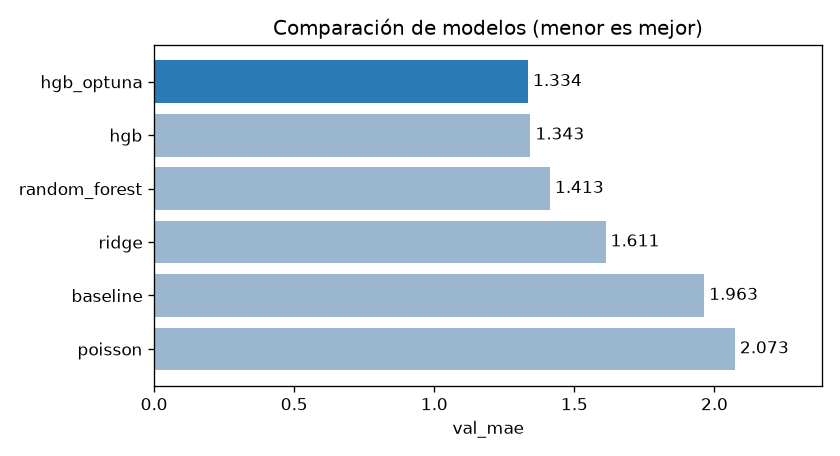

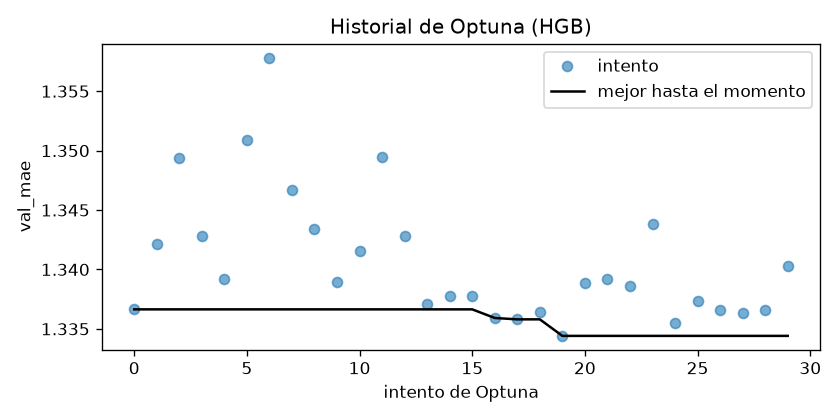

In [6]:
display(Image(FIGURES_DIR / "fase2_comparacion_modelos.png"))
display(Image(FIGURES_DIR / "fase2_optuna_historial.png"))

## 5. Model Registry: versiones, alias y métricas

In [7]:
cliente = MlflowClient()
nombre = params["mlflow"]["modelo_registrado"]
alias = {v: a for a, v in cliente.get_registered_model(nombre).aliases.items()}
pd.DataFrame([{
    "version": int(v.version),
    "alias": alias.get(v.version, ""),
    "modelo": v.tags.get("modelo"),
    "val_mae": float(v.tags.get("val_mae")),
    "test_mae": float(v.tags.get("test_mae")),
    "run_id": v.run_id[:8],
} for v in cliente.search_model_versions(f"name='{nombre}'")]).sort_values("version", ascending=False)

,version,alias,modelo,val_mae,test_mae,run_id
0,5,,poisson,2.0729,2.0457,29d62819
1,4,,ridge,1.6114,1.6512,4d5119b1
2,3,,random_forest,1.4126,1.5081,fe3d06aa
3,2,challenger,hgb,1.3429,1.4469,7584341e
4,1,champion,hgb_optuna,1.3344,1.4413,7c0a4aea


## 6. Modelo campeón: desempeño en prueba y tipos de estación

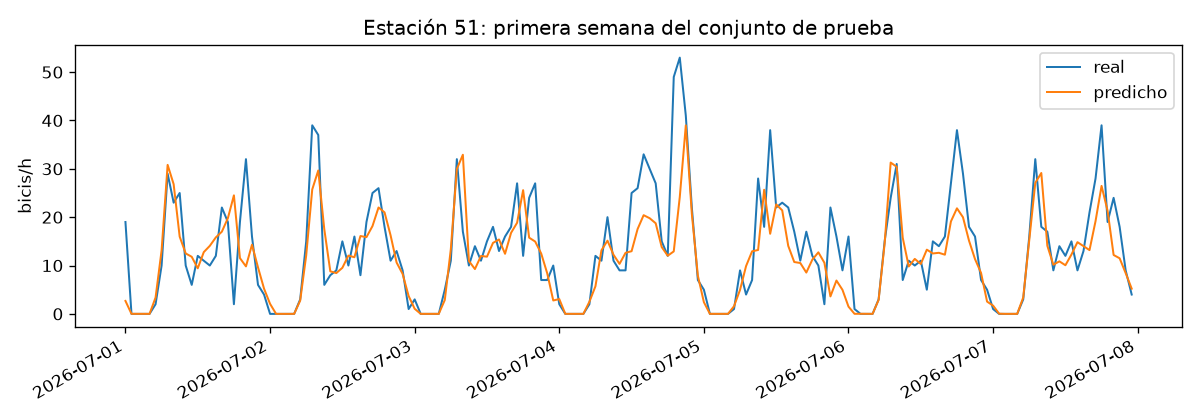

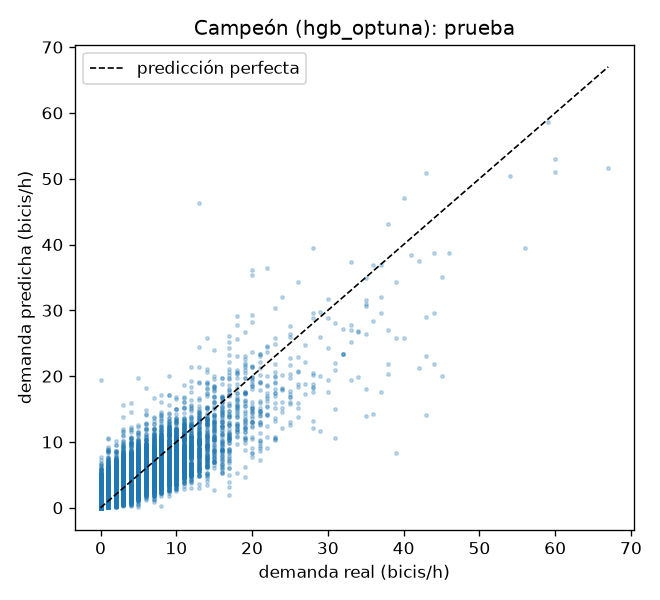

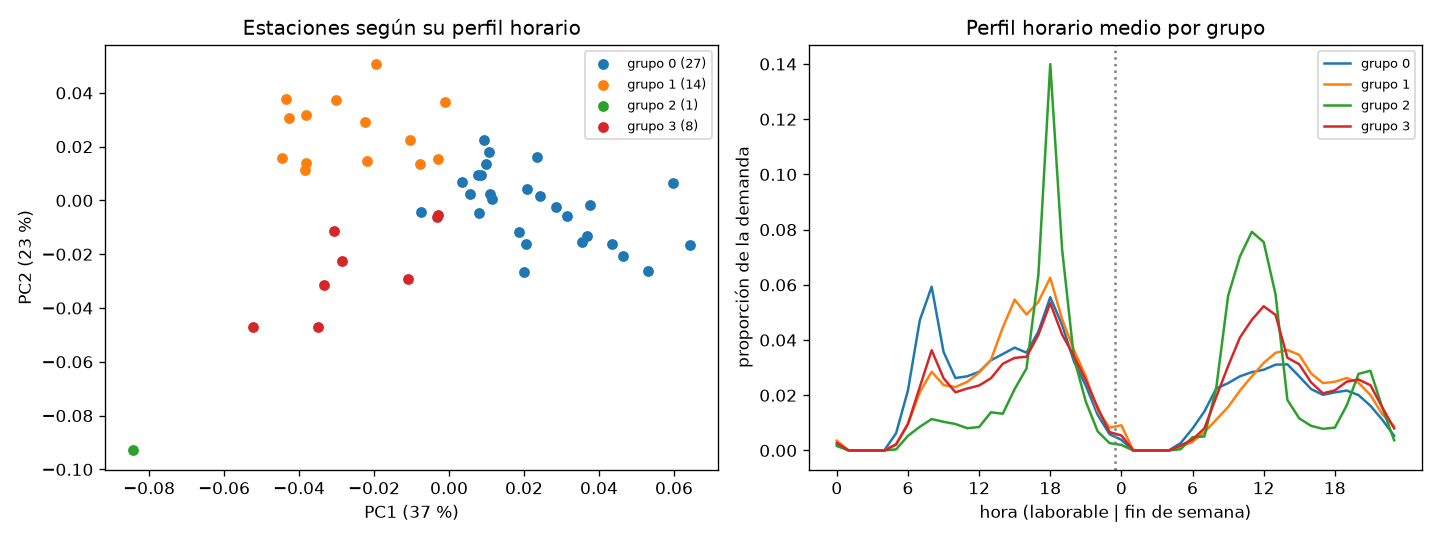

In [8]:
for archivo in ("fase2_campeon_serie_test.png", "fase2_campeon_real_vs_predicho_test.png",
                "fase2_perfiles_pca_estaciones.png"):
    display(Image(FIGURES_DIR / archivo))

## 7. Inferencia con el alias `@champion`

`predict.py` carga el modelo por alias, no por número de versión: si un reentrenamiento promueve
otro modelo, el código de inferencia no cambia.

In [9]:
modelo = cargar_modelo("champion", params)
muestra = tabla[tabla["fecha_hora"] >= params["particion"]["corte_test"]].tail(24)
predecir(muestra, modelo, params).round(2)

2026-11-08 01:04:17.415 | INFO     | tc5044_mlops.tracking:configurar_mlflow:85 - MLflow tracking: http://127.0.0.1:5000
2026-11-08 01:04:17.415 | INFO     | tc5044_mlops.modeling.predict:cargar_modelo:36 - Cargando models:/mibici-demanda-estacion-hora@champion


/tmp/ipykernel_4299/133752877.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  predecir(muestra, modelo, params).round(2)


,origen_id,fecha_hora,demanda,prediccion
729576,333,2026-08-31 00:00:00,0,1.09
729577,333,2026-08-31 01:00:00,0,0.00
729578,333,2026-08-31 02:00:00,0,0.00
729579,333,2026-08-31 03:00:00,0,0.00
729580,333,2026-08-31 04:00:00,0,0.00
729581,333,2026-08-31 05:00:00,0,0.79
729582,333,2026-08-31 06:00:00,1,2.72
729583,333,2026-08-31 07:00:00,6,3.66
729584,333,2026-08-31 08:00:00,11,4.46
729585,333,2026-08-31 09:00:00,2,3.77
